In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
print('Distribusi kelas target (1: Hoaks, 0: Valid):')
print(df['label'].value_counts())
df.head()


Dimensi data: (1498, 2)
Distribusi kelas target (1: Hoaks, 0: Valid):
label
1    749
0    749
Name: count, dtype: int64


,teks_bersih,label
0,presiden prabowo minta maaf ikut bop akan kemb...,1
1,video presiden prabowo akan membagikan bantuan...,1
2,pemerintah kota tangerang selatan akan legalka...,1
3,tautan rekrutmen cpns kementerian imigrasi,1
4,ramuan rebusan jahe kunyit kencur dan serai be...,1


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X = df['teks_bersih']
y = df['label']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=1000)
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

print('Dimensi data latih:', X_train.shape)
print('Dimensi data uji  :', X_test.shape)


Dimensi data latih: (1198, 1000)
Dimensi data uji  : (300, 1000)


In [3]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

kernels = ['linear', 'rbf', 'poly']
hasil_kernel = {}

for k in kernels:
    svm = SVC(kernel=k, random_state=42)
    svm.fit(X_train, y_train)
    acc = accuracy_score(y_test, svm.predict(X_test))
    hasil_kernel[k] = acc
    print(f'Akurasi SVM Kernel {k:6s}: {acc * 100:.2f}%')


Akurasi SVM Kernel linear: 87.67%
Akurasi SVM Kernel rbf   : 89.33%


Akurasi SVM Kernel poly  : 88.00%


In [4]:
from sklearn.model_selection import GridSearchCV

# Tuning parameter C untuk SVM Linear dan RBF
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print('Parameter Terbaik:', grid.best_params_)
print(f'Akurasi CV Terbaik: {grid.best_score_ * 100:.2f}%')


Parameter Terbaik: {'C': 10, 'kernel': 'rbf'}
Akurasi CV Terbaik: 90.32%


In [5]:
from sklearn.metrics import classification_report, confusion_matrix

best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test)

acc_test = accuracy_score(y_test, y_pred)
print(f'Akurasi Data Uji: {acc_test * 100:.2f}%')
print('Classification Report SVM:')
print(classification_report(y_test, y_pred, target_names=['Valid', 'Hoaks']))


Akurasi Data Uji: 89.67%
Classification Report SVM:
              precision    recall  f1-score   support

       Valid       0.89      0.90      0.90       150
       Hoaks       0.90      0.89      0.90       150

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



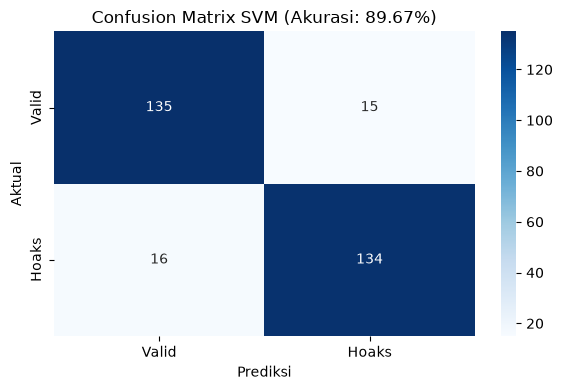

In [6]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Valid', 'Hoaks'], yticklabels=['Valid', 'Hoaks'])
plt.title(f'Confusion Matrix SVM (Akurasi: {acc_test*100:.2f}%)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()
